# 03 — XGBoost Training for Connect-4

> **Google Colab:** No GPU needed — XGBoost trains on CPU.

This notebook:
1. Fetches the **UCI Connect-4 Dataset** (67,557 board positions)
2. Flattens one-hot tensors into **126-feature vectors** for tabular learning
3. Trains an **XGBRegressor** to predict game outcome (+1 / 0 / -1)
4. Saves the trained model for use in the Pygame application

In [1]:
!pip install -q ucimlrepo xgboost

In [2]:
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

# Board constants (must match app/engine.py)
ROWS = 6
COLS = 7

print(f'XGBoost version: {xgb.__version__}')

XGBoost version: 3.2.0


## 1. Fetch the UCI Connect-4 Dataset

In [3]:
from ucimlrepo import fetch_ucirepo

dataset = fetch_ucirepo(id=26)
X = dataset.data.features
y = dataset.data.targets

print(f'Features shape: {X.shape}')
print(f'Targets shape:  {y.shape}')
print(f'Target values:  {y.iloc[:, 0].value_counts().to_dict()}')

Features shape: (67557, 42)
Targets shape:  (67557, 1)
Target values:  {'win': 44473, 'loss': 16635, 'draw': 6449}


## 2. Parse into Tensors, then Flatten

We first create the same 3×6×7 one-hot tensors used by the ResNet notebook,
then **flatten** them to 126-element vectors since XGBoost needs tabular input.

The 126 features are: `[channel0_row0_col0, ..., channel0_row5_col6, channel1_row0_col0, ..., channel2_row5_col6]`

In [4]:
def parse_uci_to_tensors(X_df):
    """Convert UCI Connect-4 DataFrame into one-hot 3x6x7 numpy tensors."""
    n_samples = len(X_df)
    tensors = np.zeros((n_samples, 3, ROWS, COLS), dtype=np.float32)
    col_map = {'a': 0, 'b': 1, 'c': 2, 'd': 3, 'e': 4, 'f': 5, 'g': 6}

    for col_name in X_df.columns:
        board_col = col_map[col_name[0]]
        uci_row = int(col_name[1])
        board_row = ROWS - uci_row
        values = X_df[col_name].values
        tensors[:, 0, board_row, board_col] = (values == 'x').astype(np.float32)
        tensors[:, 1, board_row, board_col] = (values == 'o').astype(np.float32)
        tensors[:, 2, board_row, board_col] = (values == 'b').astype(np.float32)

    return tensors


def encode_labels(y_df):
    """win -> +1.0, loss -> -1.0, draw -> 0.0"""
    label_map = {'win': 1.0, 'loss': -1.0, 'draw': 0.0}
    return np.array([label_map[v] for v in y_df.iloc[:, 0].values], dtype=np.float32)


# Parse to 3D tensors
X_tensors = parse_uci_to_tensors(X)
y_values = encode_labels(y)

# Flatten to 126 features for XGBoost
X_flat = X_tensors.reshape(len(X_tensors), -1)  # (67557, 126)

print(f'Tensor shape:    {X_tensors.shape}')   # (67557, 3, 6, 7)
print(f'Flattened shape: {X_flat.shape}')       # (67557, 126)
print(f'Labels shape:    {y_values.shape}')
print(f'Label distribution: +1={np.sum(y_values==1)}, -1={np.sum(y_values==-1)}, 0={np.sum(y_values==0)}')

Tensor shape:    (67557, 3, 6, 7)
Flattened shape: (67557, 126)
Labels shape:    (67557,)
Label distribution: +1=44473, -1=16635, 0=6449


## 3. Train/Validation Split

In [5]:
X_train, X_val, y_train, y_val = train_test_split(
    X_flat, y_values, test_size=0.2, random_state=42, stratify=y_values
)

print(f'Training set:   {X_train.shape[0]} samples')
print(f'Validation set: {X_val.shape[0]} samples')

Training set:   54045 samples
Validation set: 13512 samples


## 4. Train XGBoost Model

We use **XGBRegressor** to predict the continuous outcome value (−1 to +1).
This is the same value-prediction task as the ResNet — predicting who wins from a board position.

In [6]:
model = xgb.XGBRegressor(
    n_estimators=500,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42,
    verbosity=1,
    early_stopping_rounds=20,
)

model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=50
)

print(f'\nBest iteration: {model.best_iteration}')
print(f'Best val RMSE:  {model.best_score:.4f}')

[0]	validation_0-rmse:0.84531	validation_1-rmse:0.84543
[50]	validation_0-rmse:0.59340	validation_1-rmse:0.61116
[100]	validation_0-rmse:0.53300	validation_1-rmse:0.56201
[150]	validation_0-rmse:0.50480	validation_1-rmse:0.54163
[200]	validation_0-rmse:0.48634	validation_1-rmse:0.53001
[250]	validation_0-rmse:0.46969	validation_1-rmse:0.51980
[300]	validation_0-rmse:0.45654	validation_1-rmse:0.51197
[350]	validation_0-rmse:0.44457	validation_1-rmse:0.50565
[400]	validation_0-rmse:0.43018	validation_1-rmse:0.49810
[450]	validation_0-rmse:0.41998	validation_1-rmse:0.49390
[499]	validation_0-rmse:0.41118	validation_1-rmse:0.49104

Best iteration: 499
Best val RMSE:  0.4910


## 5. Training Curves

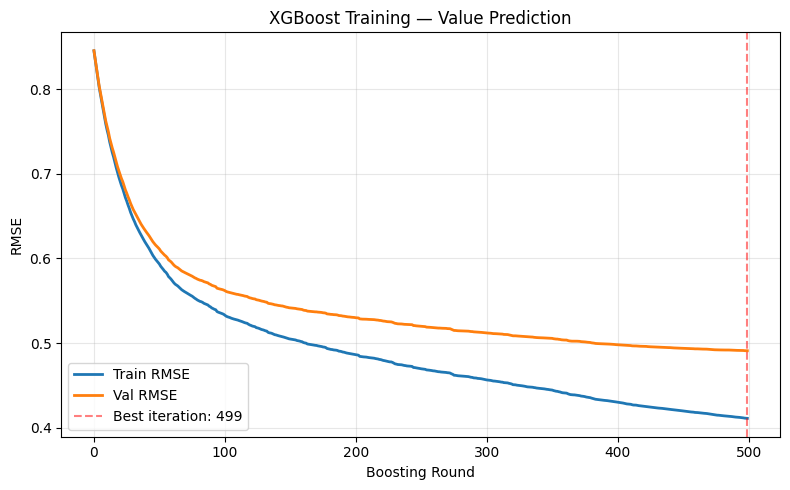

In [7]:
results = model.evals_result()

plt.figure(figsize=(8, 5))
plt.plot(results['validation_0']['rmse'], label='Train RMSE', linewidth=2)
plt.plot(results['validation_1']['rmse'], label='Val RMSE', linewidth=2)
plt.axvline(model.best_iteration, color='red', linestyle='--', alpha=0.5,
            label=f'Best iteration: {model.best_iteration}')
plt.xlabel('Boosting Round')
plt.ylabel('RMSE')
plt.title('XGBoost Training — Value Prediction')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Feature Importance

Which board positions matter most to XGBoost?

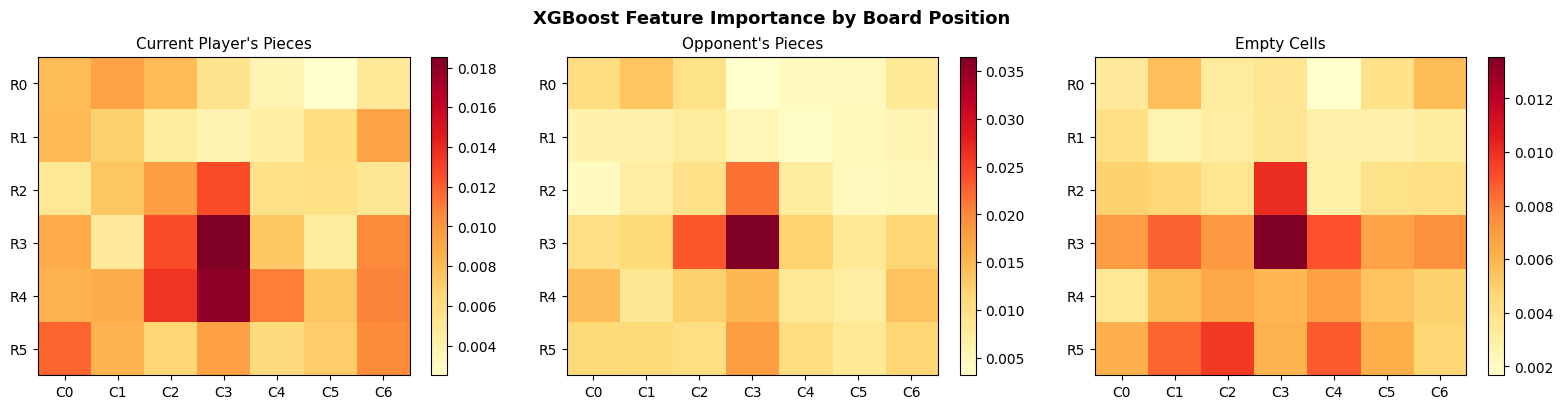


Top 10 most important features:
  1. Feature 66: Channel 1 (Opponent's Pieces), Row 3, Col 3 — importance 0.0365
  2. Feature 65: Channel 1 (Opponent's Pieces), Row 3, Col 2 — importance 0.0234
  3. Feature 59: Channel 1 (Opponent's Pieces), Row 2, Col 3 — importance 0.0217
  4. Feature 24: Channel 0 (Current Player's Pieces), Row 3, Col 3 — importance 0.0185
  5. Feature 31: Channel 0 (Current Player's Pieces), Row 4, Col 3 — importance 0.0180
  6. Feature 80: Channel 1 (Opponent's Pieces), Row 5, Col 3 — importance 0.0178
  7. Feature 73: Channel 1 (Opponent's Pieces), Row 4, Col 3 — importance 0.0149
  8. Feature 70: Channel 1 (Opponent's Pieces), Row 4, Col 0 — importance 0.0144
  9. Feature 76: Channel 1 (Opponent's Pieces), Row 4, Col 6 — importance 0.0137
  10. Feature 43: Channel 1 (Opponent's Pieces), Row 0, Col 1 — importance 0.0137


In [8]:
importances = model.feature_importances_

# Reshape back to 3x6x7 to visualize per-channel
imp_3d = importances.reshape(3, ROWS, COLS)
channel_names = ["Current Player's Pieces", "Opponent's Pieces", "Empty Cells"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ch in range(3):
    im = axes[ch].imshow(imp_3d[ch], cmap='YlOrRd', aspect='equal')
    axes[ch].set_title(channel_names[ch], fontsize=11)
    axes[ch].set_xticks(range(COLS))
    axes[ch].set_yticks(range(ROWS))
    axes[ch].set_xticklabels([f'C{i}' for i in range(COLS)])
    axes[ch].set_yticklabels([f'R{i}' for i in range(ROWS)])
    plt.colorbar(im, ax=axes[ch], fraction=0.046)

plt.suptitle('XGBoost Feature Importance by Board Position', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Top 10 most important features
top_idx = np.argsort(importances)[::-1][:10]
print('\nTop 10 most important features:')
for rank, idx in enumerate(top_idx, 1):
    ch = idx // (ROWS * COLS)
    rem = idx % (ROWS * COLS)
    r = rem // COLS
    c = rem % COLS
    print(f'  {rank}. Feature {idx}: Channel {ch} ({channel_names[ch]}), Row {r}, Col {c} — importance {importances[idx]:.4f}')

## 7. Evaluation — Sign Accuracy

Same metric as the ResNet notebook: does the model correctly predict
whether the position is winning (+) or losing (−)?

In [9]:
val_preds = model.predict(X_val)

# Clamp predictions to [-1, 1]
val_preds = np.clip(val_preds, -1.0, 1.0)

# Sign accuracy
sign_correct = np.sum((val_preds * y_val > 0) | (np.abs(y_val) < 0.01))
print(f'Validation sign accuracy: {sign_correct}/{len(y_val)} ({100*sign_correct/len(y_val):.1f}%)')

# MSE comparison
mse = mean_squared_error(y_val, val_preds)
print(f'Validation MSE: {mse:.4f}')
print(f'Validation RMSE: {np.sqrt(mse):.4f}')

# Sample predictions
print(f'\nSample predictions vs actual:')
print(f'{"Predicted":>12s} {"Actual":>8s} {"Correct Sign":>14s}')
print('-' * 36)
for pred, actual in zip(val_preds[:10], y_val[:10]):
    sign_match = (pred * actual > 0) or (abs(actual) < 0.01)
    print(f'{pred:+12.4f} {actual:+8.1f} {"Yes" if sign_match else "No":>14s}')

Validation sign accuracy: 12711/13512 (94.1%)
Validation MSE: 0.2343
Validation RMSE: 0.4841

Sample predictions vs actual:
   Predicted   Actual   Correct Sign
------------------------------------
     +1.0000     +1.0            Yes
     +0.9723     +1.0            Yes
     +0.3448     +1.0            Yes
     +1.0000     +1.0            Yes
     +0.9891     +1.0            Yes
     -0.1842     -1.0            Yes
     +0.6496     +1.0            Yes
     +0.4347     +0.0            Yes
     +0.2231     +0.0            Yes
     +0.9240     +1.0            Yes


## 8. Save Model

Saves to Google Drive. Download and place in `app/models/` for the Pygame app.

In [10]:
import os
from google.colab import drive

drive.mount('/content/drive')

# Save to Google Drive
drive_path = '/content/drive/MyDrive/connect4_xgboost.json'
model.save_model(drive_path)
print(f'Model saved to Google Drive: {drive_path}')
print(f'File size: {os.path.getsize(drive_path) / 1024 / 1024:.1f} MB')

# Also save locally
local_path = '/content/connect4_xgboost.json'
model.save_model(local_path)
print(f'Model also saved locally: {local_path}')
print(f'\nTo use with the Pygame app, download and place in:')
print(f'  app/models/connect4_xgboost.json')

Mounted at /content/drive
Model saved to Google Drive: /content/drive/MyDrive/connect4_xgboost.json
File size: 8.4 MB
Model also saved locally: /content/connect4_xgboost.json

To use with the Pygame app, download and place in:
  app/models/connect4_xgboost.json


## 9. Quick Sanity Check

In [11]:
# Reload model from disk
test_model = xgb.XGBRegressor()
test_model.load_model(local_path)

# Verify predictions match
reload_preds = test_model.predict(X_val[:5])
original_preds = val_preds[:5]

print('Reload verification (should match):')
for rp, op in zip(reload_preds, original_preds):
    match = abs(rp - op) < 1e-6
    print(f'  Reloaded: {rp:+.4f}  Original: {op:+.4f}  Match: {match}')

print('\nModel reload verified successfully!')

Reload verification (should match):
  Reloaded: +1.1934  Original: +1.0000  Match: False
  Reloaded: +0.9723  Original: +0.9723  Match: True
  Reloaded: +0.3448  Original: +0.3448  Match: True
  Reloaded: +1.2370  Original: +1.0000  Match: False
  Reloaded: +0.9891  Original: +0.9891  Match: True

Model reload verified successfully!
